In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 100

try:
    df = sns.load_dataset("iris")
except Exception:
    # Offline fallback: same data from scikit-learn
    from sklearn.datasets import load_iris
    raw = load_iris()
    df = pd.DataFrame(raw.data, columns=["sepal_length", "sepal_width", "petal_length", "petal_width"])
    df["species"] = pd.Categorical.from_codes(raw.target, raw.target_names)

features = ["sepal_length", "sepal_width", "petal_length", "petal_width"]
print(df.shape)
df.head()

(150, 5)


,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [2]:
print(df["species"].value_counts())
df.describe().round(2)

species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


,sepal_length,sepal_width,petal_length,petal_width
count,150.00,150.00,150.00,150.00
mean,5.84,3.06,3.76,1.20
std,0.83,0.44,1.77,0.76
min,4.30,2.00,1.00,0.10
25%,5.10,2.80,1.60,0.30
50%,5.80,3.00,4.35,1.30
75%,6.40,3.30,5.10,1.80
max,7.90,4.40,6.90,2.50


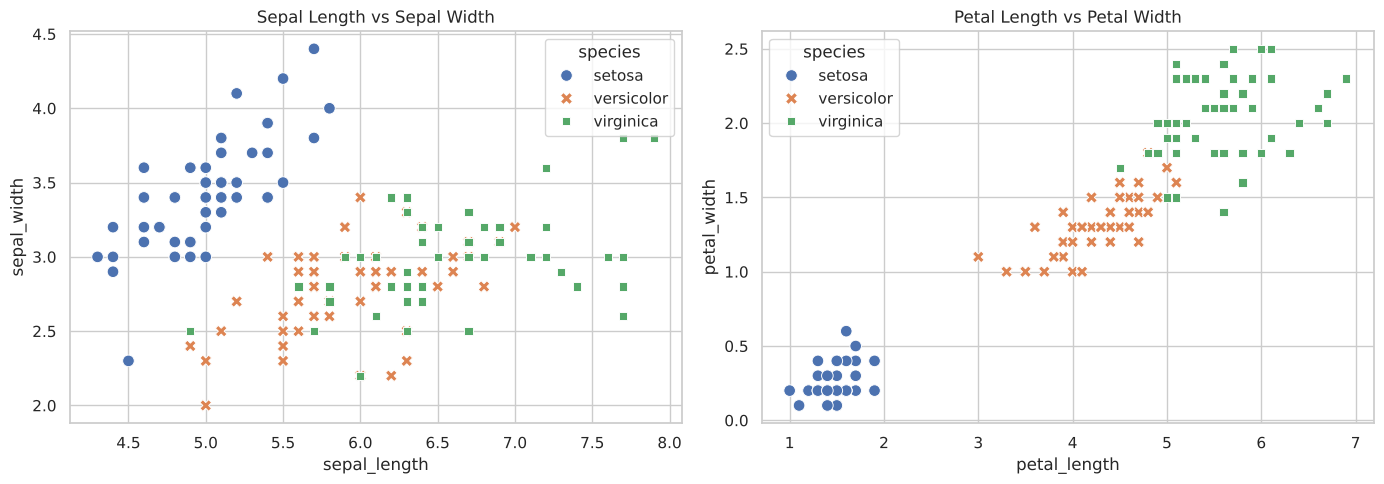

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.scatterplot(data=df, x="sepal_length", y="sepal_width", hue="species", style="species", s=70, ax=axes[0])
axes[0].set_title("Sepal Length vs Sepal Width")

sns.scatterplot(data=df, x="petal_length", y="petal_width", hue="species", style="species", s=70, ax=axes[1])
axes[1].set_title("Petal Length vs Petal Width")

plt.tight_layout()
plt.show()

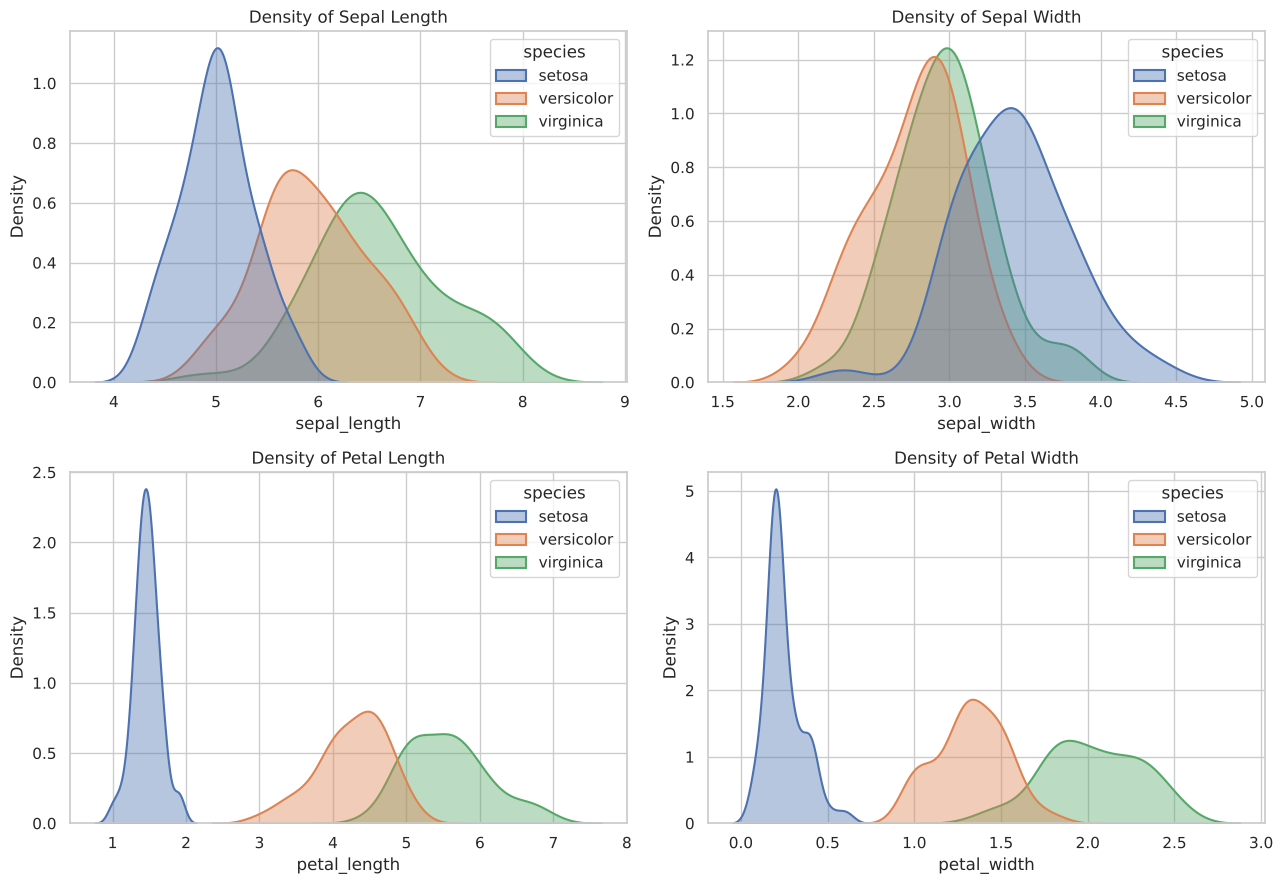

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for ax, col in zip(axes.ravel(), features):
    sns.kdeplot(data=df, x=col, hue="species", fill=True, common_norm=False, alpha=0.4, linewidth=1.5, ax=ax)
    ax.set_title(f"Density of {col.replace('_', ' ').title()}")
plt.tight_layout()
plt.show()

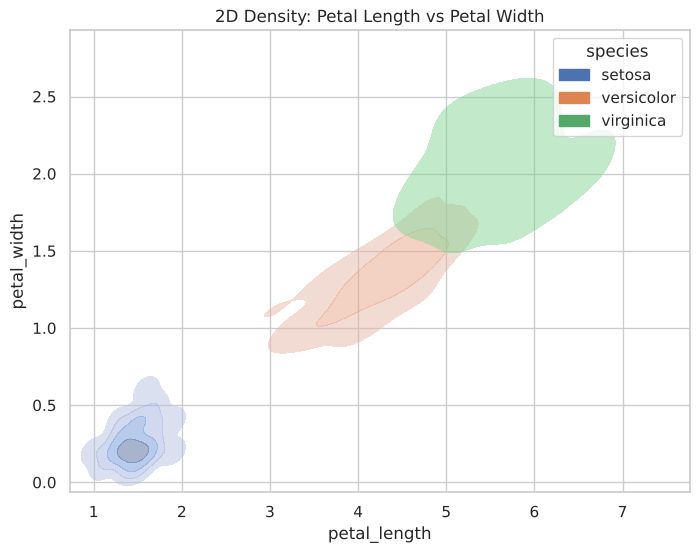

In [5]:
# Bivariate density: petal length vs petal width
plt.figure(figsize=(8, 6))
sns.kdeplot(data=df, x="petal_length", y="petal_width", hue="species", fill=True, alpha=0.5, levels=5)
plt.title("2D Density: Petal Length vs Petal Width")
plt.show()

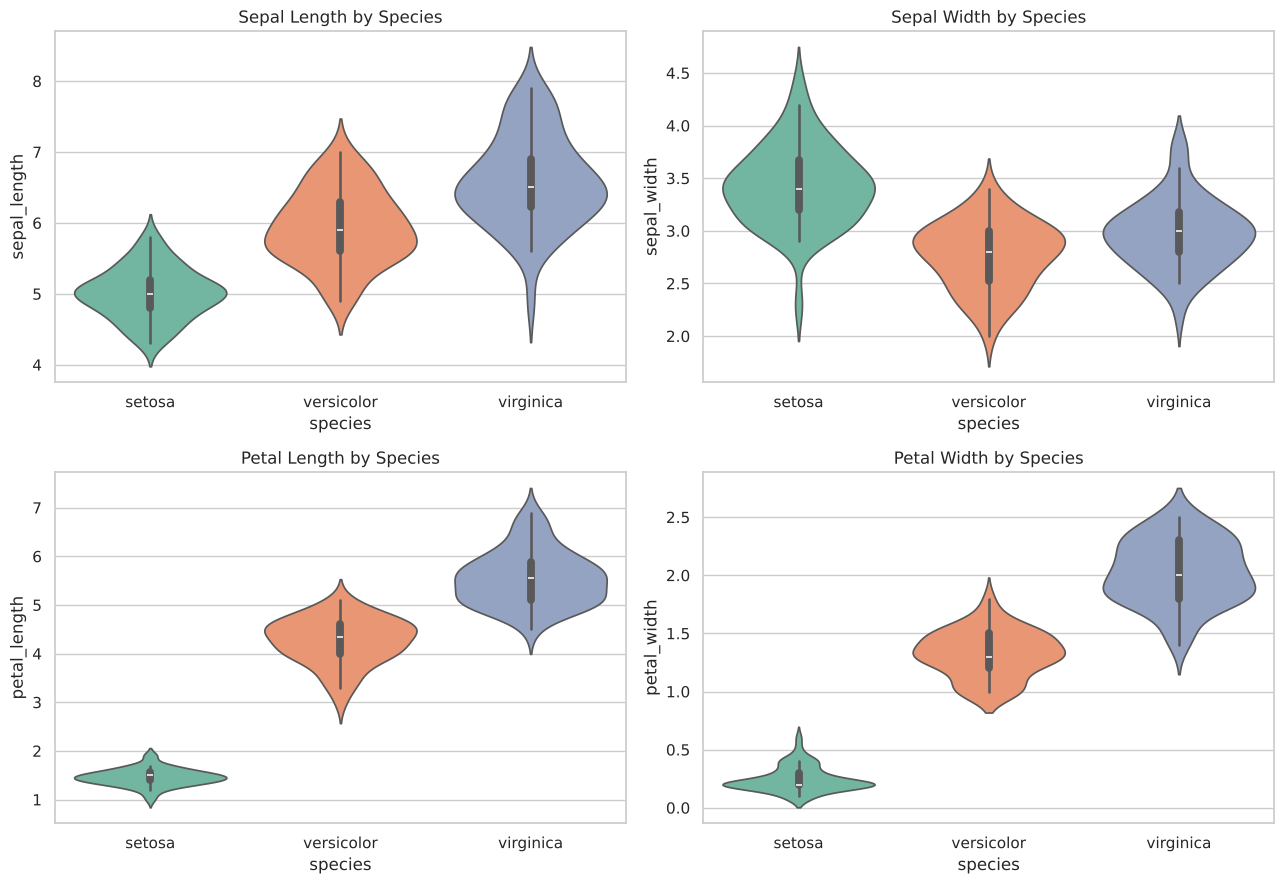

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for ax, col in zip(axes.ravel(), features):
    sns.violinplot(data=df, x="species", y=col, hue="species", inner="box", palette="Set2", legend=False, ax=ax)
    ax.set_title(f"{col.replace('_', ' ').title()} by Species")
plt.tight_layout()
plt.show()

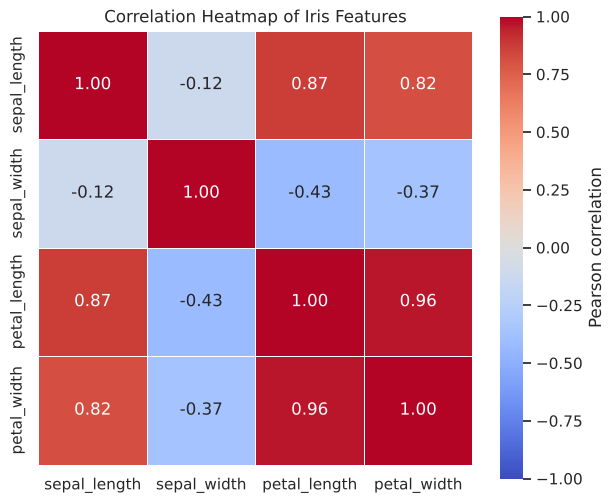

In [7]:
corr = df[features].corr()
plt.figure(figsize=(7, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True, linewidths=0.5, cbar_kws={"label": "Pearson correlation"})
plt.title("Correlation Heatmap of Iris Features")
plt.show()

In [8]:
# Correlation within each species (to check for Simpson's-paradox-like effects)
for sp, g in df.groupby("species", observed=True):
    print(f"\n{sp}")
    print(g[features].corr().round(2))


setosa
              sepal_length  sepal_width  petal_length  petal_width
sepal_length          1.00         0.74          0.27         0.28
sepal_width           0.74         1.00          0.18         0.23
petal_length          0.27         0.18          1.00         0.33
petal_width           0.28         0.23          0.33         1.00

versicolor
              sepal_length  sepal_width  petal_length  petal_width
sepal_length          1.00         0.53          0.75         0.55
sepal_width           0.53         1.00          0.56         0.66
petal_length          0.75         0.56          1.00         0.79
petal_width           0.55         0.66          0.79         1.00

virginica
              sepal_length  sepal_width  petal_length  petal_width
sepal_length          1.00         0.46          0.86         0.28
sepal_width           0.46         1.00          0.40         0.54
petal_length          0.86         0.40          1.00         0.32
petal_width           0.28     

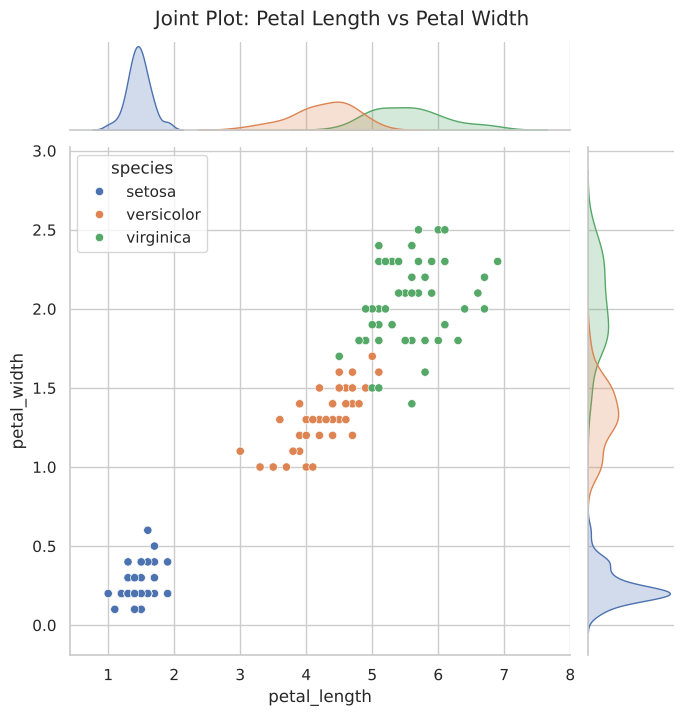

In [9]:
g = sns.jointplot(data=df, x="petal_length", y="petal_width", hue="species", height=7)
g.figure.suptitle("Joint Plot: Petal Length vs Petal Width", y=1.02)
plt.show()

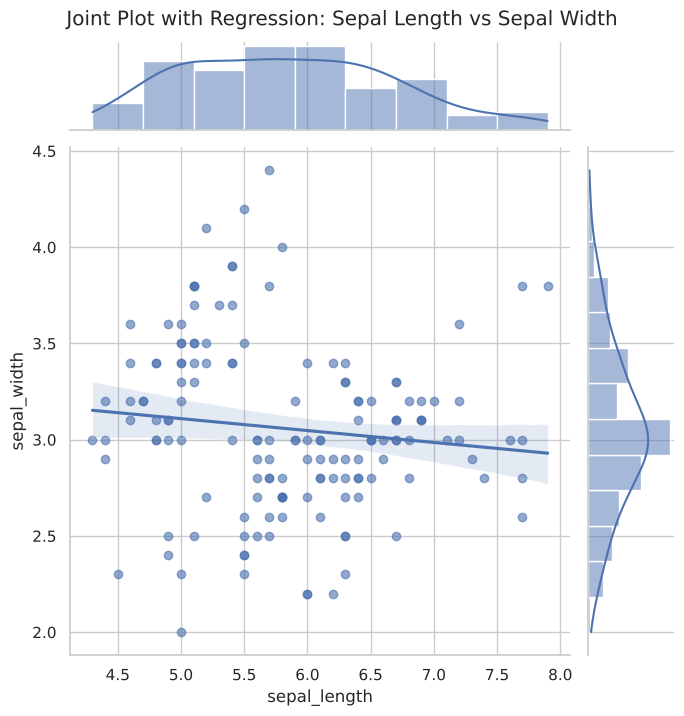

In [10]:
g = sns.jointplot(data=df, x="sepal_length", y="sepal_width", kind="reg", height=7, scatter_kws={"alpha": 0.6})
g.figure.suptitle("Joint Plot with Regression: Sepal Length vs Sepal Width", y=1.02)
plt.show()

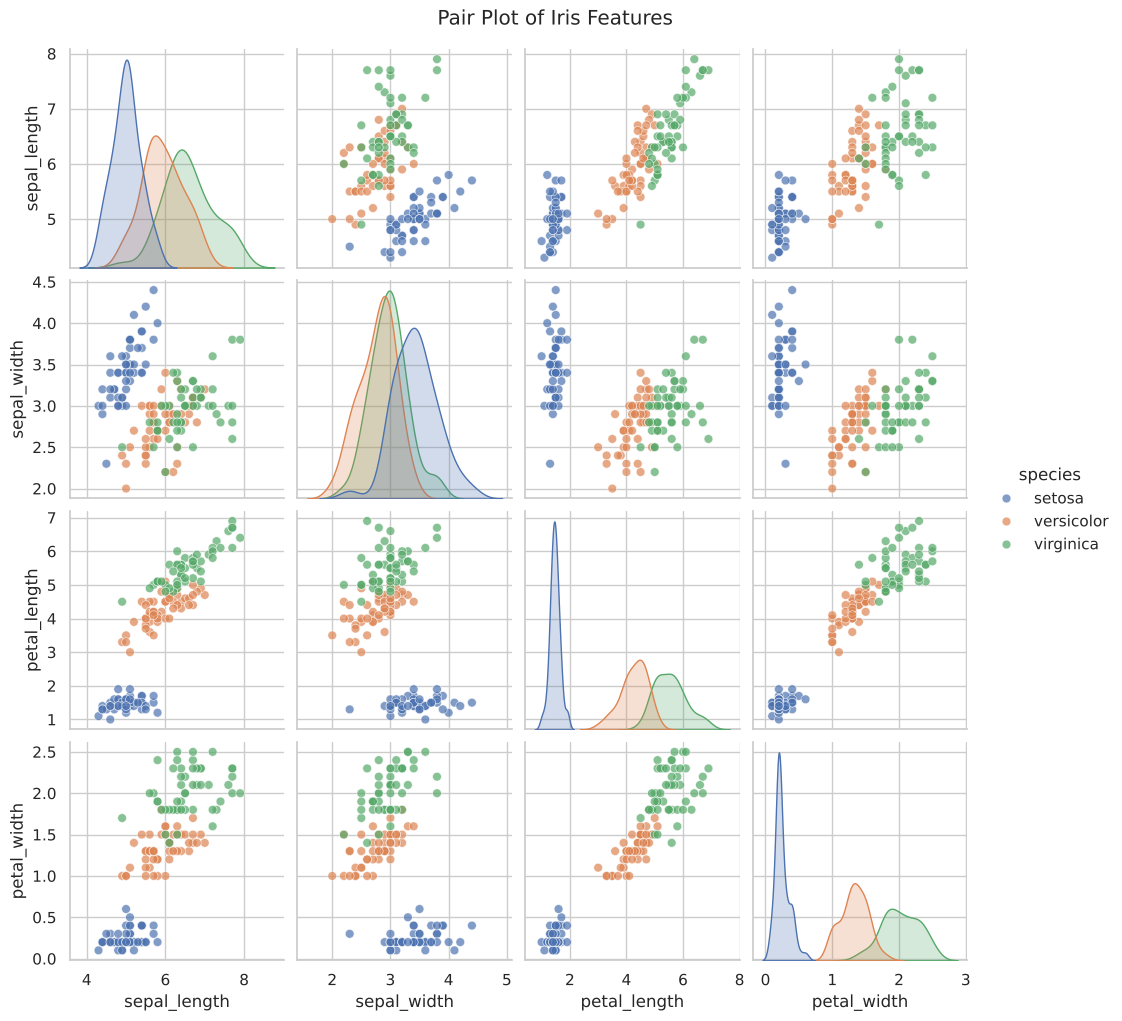

In [11]:
g = sns.pairplot(df, hue="species", diag_kind="kde", corner=False, plot_kws={"alpha": 0.7, "s": 40})
g.figure.suptitle("Pair Plot of Iris Features", y=1.02)
plt.show()